# Tier 3 B: DQN improvements on LunarLander-v3 (discrete)

Same environment, budget and evaluation protocol as Tier 2. We compare **vanilla DQN** (the Tier 2 default) with:

1. **Double DQN**: decouples action selection and evaluation in the target to reduce overestimation.
2. **Dueling DQN**: splits the network into a state-value stream $V(s)$ and an advantage stream $A(s,a)$.
3. **Double + Dueling**.
4. **Double + Dueling + Prioritized Experience Replay (PER)** (optional extension).

Only the improvement changes between configurations; every other hyperparameter is the Tier 2 default.

## 0. Setup

Requires `pip install "gymnasium[box2d]" torch matplotlib pillow joblib`.

In [2]:
import copy
import json
import os
import platform
import random
import time
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image as ShowImage, Markdown, display
from PIL import Image

torch.set_num_threads(1)   # the network is small: 1 thread is faster


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


HARDWARE = f"{platform.processor() or platform.machine()}, {os.cpu_count()} CPUs, {platform.system()}"
print("python", platform.python_version(), "| torch", torch.__version__,
      "| gymnasium", gym.__version__, "| numpy", np.__version__)
print("hardware:", HARDWARE)

python 3.11.9 | torch 2.10.0+cpu | gymnasium 1.2.3 | numpy 2.2.6
hardware: Intel64 Family 6 Model 183 Stepping 1, GenuineIntel, 32 CPUs, Windows


### Configuration

| | Value |
| --- | --- |
| Step budget | 500,000 environment steps per run (same for every configuration, same as Tier 2) |
| Seeds | 5 per configuration (0–4) |
| Evaluation | 10 greedy episodes (ε = 0) every 10,000 steps; 100 greedy episodes at the end |
| Success threshold | mean return ≥ 200 over 100 episodes |
| γ | 0.99 |
| Shared DQN settings (Tier 2 default) | Adam lr 5e-4, buffer 100k, batch 128, warmup 10k, one update every 4 steps, target update every C = 1,000 steps, ε 1.0 → 0.05 in 100k steps, Huber loss, gradient-norm clip 10 |
| PER | proportional, α = 0.6, β 0.4 → 1.0 linearly over the budget, new transitions get the current max priority |

In [3]:
ENV_ID = "LunarLander-v3"
SUCCESS_THRESHOLD = 200   # solved: mean return >= 200 over 100 episodes
GAMMA = 0.99

STEP_BUDGET = 500_000
SEEDS = [0, 1, 2, 3, 4]
EVAL_EVERY = 10_000
EVAL_EPISODES = 10     # episodes in each evaluation during training
FINAL_EPISODES = 100   # episodes in the final evaluation

# runs trained at the same time (each run uses 1 CPU thread). Use 1 for fully sequential training.
N_JOBS = max(1, min(12, (os.cpu_count() or 2) - 1))

RESULTS_DIR = Path("results/tier3")
LOG_DIR = RESULTS_DIR / "logs"       # metrics of each run (JSON)
MODEL_DIR = RESULTS_DIR / "models"   # network weights
FIG_DIR = RESULTS_DIR / "figures"    # plots and GIFs
for folder in [LOG_DIR, MODEL_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print(f"steps per run: {STEP_BUDGET:,} | seeds: {SEEDS} | evaluate every {EVAL_EVERY:,} steps | parallel runs: {N_JOBS}")

steps per run: 500,000 | seeds: [0, 1, 2, 3, 4] | evaluate every 10,000 steps | parallel runs: 12


## 1. Environment (recap from Tier 2)

| Element | LunarLander-v3 (discrete) |
| --- | --- |
| State | 8 continuous: x, y, vx, vy, angle, angular velocity, left leg contact, right leg contact |
| Actions | 4 discrete: nothing (0), left engine (1), main engine (2), right engine (3) |
| Reward | shaping towards the pad, engine costs, +10 per leg contact, +100 landing / −100 crash |
| End | `terminated`: crash, out of the screen, or lander at rest. `truncated`: 1,000 steps |

Why these improvements are relevant here: rewards are large (±100) and noisy, so the $\max$ in the DQN target tends to **overestimate** Q-values (Double DQN); in many states (e.g. high in the air) the choice of action barely matters, which is what the **dueling** split $V + A$ is designed for; and the informative transitions (landings and crashes) are rare in the buffer, which is what **prioritized replay** targets.

In [4]:
env = gym.make(ENV_ID)
print("observation space:", env.observation_space)
print("action space     :", env.action_space)
print("max episode steps:", env.spec.max_episode_steps)

# random policy as a baseline
returns = []
env.action_space.seed(0)
for k in range(100):
    state, _ = env.reset(seed=k)
    done, total = False, 0.0
    while not done:
        state, reward, terminated, truncated, _ = env.step(env.action_space.sample())
        total += reward
        done = terminated or truncated
    returns.append(total)
env.close()
RANDOM_RETURN = float(np.mean(returns))
print(f"random policy (100 episodes): return {np.mean(returns):.1f} ± {np.std(returns):.1f}")

observation space: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
action space     : Discrete(4)
max episode steps: 1000
random policy (100 episodes): return -192.1 ± 114.4


## 2. Evaluation and logging

Same protocol as Tiers 1–2 (greedy evaluation in a separate environment with fixed seeds; training time excludes evaluation).

New in Tier 3: during each evaluation we also measure the **overestimation** of the network. At every state visited by the greedy policy we record the predicted value $\max_a Q(s,a)$ and, once the episode ends, the **actual** discounted return obtained from that state, $G_t = \sum_k \gamma^k r_{t+k}$. The gap $\overline{Q} - \overline{G}$ is the estimation bias (positive = overestimation). (Near a 1,000-step truncation $G_t$ is cut short, so the bias is slightly inflated for policies that hover.)

In [5]:
def epsilon_by_step(i, eps_start, eps_end, eps_decay):
    fraction = min(1.0, i / eps_decay)
    return eps_start + fraction * (eps_end - eps_start)


EVAL_SEED = 100_000    # evaluation seeds: different from the training seeds
FINAL_SEED = 200_000   # seeds of the final 100-episode evaluation


def evaluate(q_net, num_episodes, first_seed, gamma=GAMMA):
    # Greedy evaluation. Returns (returns of each episode, mean predicted Q, mean actual discounted return)
    env = gym.make(ENV_ID)
    returns, q_pred, g_true = [], [], []
    for k in range(num_episodes):
        state, _ = env.reset(seed=first_seed + k)
        done = False
        rewards = []
        while not done:
            with torch.no_grad():
                q = q_net(torch.as_tensor(state, dtype=torch.float32).unsqueeze(0))[0]
            action = int(q.argmax().item())
            q_pred.append(float(q.max().item()))
            state, reward, terminated, truncated, _ = env.step(action)
            rewards.append(reward)
            done = terminated or truncated
        returns.append(float(np.sum(rewards)))
        g = 0.0                                   # discounted return-to-go, computed backwards
        to_go = []
        for r in reversed(rewards):
            g = r + gamma * g
            to_go.append(g)
        g_true.extend(to_go)
    env.close()
    return returns, float(np.mean(q_pred)), float(np.mean(g_true))


def new_log(method, seed, config):
    return {
        "method": method, "seed": seed, "config": config, "hardware": HARDWARE,
        "eval_steps": [],          # step of each evaluation
        "eval_returns": [],        # greedy return of that evaluation
        "eval_q_pred": [],         # mean max_a Q(s, a) on the visited states
        "eval_g_true": [],         # mean actual discounted return from the visited states
        "eval_time": [],           # training seconds until that evaluation
        "episode_end_steps": [],   # step where each training episode ended
        "episode_returns": [],     # return of each training episode
    }


def add_eval(log, step, q_net, train_seconds):
    returns, q_pred, g_true = evaluate(q_net, EVAL_EPISODES, EVAL_SEED)
    log["eval_steps"].append(step)
    log["eval_returns"].append(float(np.mean(returns)))
    log["eval_q_pred"].append(q_pred)
    log["eval_g_true"].append(g_true)
    log["eval_time"].append(train_seconds)


def steps_to_threshold(log):
    # First step where the evaluation reached the threshold, or None if it never did
    for step, ret in zip(log["eval_steps"], log["eval_returns"]):
        if ret >= SUCCESS_THRESHOLD:
            return step
    return None

## 3. Networks

- **`QNetwork`** (vanilla, Tier 2): MLP 8 → 256 → 256 → 4.
- **`DuelingQNetwork`**: shared layer 8 → 256, then two streams of 256 → 128 → ·
  - value stream → $V(s)$ (1 output)
  - advantage stream → $A(s,a)$ (4 outputs)

  combined as $Q(s,a) = V(s) + A(s,a) - \frac{1}{|\mathcal{A}|}\sum_{a'} A(s,a')$. Subtracting the mean makes $V$ and $A$ identifiable (otherwise any constant could move between them).

The dueling layer sizes are chosen so that both networks have almost the same number of parameters (printed below), so differences are not due to capacity.

In [6]:
class QNetwork(nn.Module):
    def __init__(self, state_dim, n_actions, hidden=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_actions),
        )

    def forward(self, x):
        return self.net(x)          # shape: (batch, n_actions)


class DuelingQNetwork(nn.Module):
    def __init__(self, state_dim, n_actions, hidden=256):
        super().__init__()
        self.trunk = nn.Sequential(nn.Linear(state_dim, hidden), nn.ReLU())
        self.value = nn.Sequential(nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Linear(hidden // 2, 1))
        self.advantage = nn.Sequential(nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Linear(hidden // 2, n_actions))

    def forward(self, x):
        h = self.trunk(x)
        v = self.value(h)                                   # (batch, 1)
        a = self.advantage(h)                               # (batch, n_actions)
        return v + a - a.mean(dim=1, keepdim=True)          # (batch, n_actions)


def count_params(net):
    return sum(p.numel() for p in net.parameters())


print("vanilla parameters:", count_params(QNetwork(8, 4)))
print("dueling parameters:", count_params(DuelingQNetwork(8, 4)))
x = torch.randn(3, 8)
print("dueling output shape:", tuple(DuelingQNetwork(8, 4)(x).shape))

vanilla parameters: 69124
dueling parameters: 68741
dueling output shape: (3, 4)


## 4. Replay buffers

- **`ReplayBuffer`**: uniform sampling (Tier 2).
- **`PrioritizedReplayBuffer`** (proportional PER, Schaul et al. 2016):
  - each transition $i$ has priority $p_i = |\delta_i| + \epsilon$ (its last TD error); new transitions get the current maximum priority so they are replayed at least once;
  - sampling probability $P(i) = p_i^\alpha / \sum_k p_k^\alpha$, stored in a **sum tree** so sampling and updates are $O(\log N)$;
  - the bias of non-uniform sampling is corrected with importance weights $w_i = (N \cdot P(i))^{-\beta} / \max_j w_j$, with β annealed from 0.4 to 1.

The sum tree below is vectorized over the mini-batch (one loop per tree level instead of per sample).

In [7]:
class ReplayBuffer:
    def __init__(self, capacity, state_dim):
        self.N = capacity
        self.c = 0                                   # transitions ever added
        self.s    = np.zeros((capacity, state_dim), dtype=np.float32)
        self.a    = np.zeros(capacity, dtype=np.int64)
        self.r    = np.zeros(capacity, dtype=np.float32)
        self.s2   = np.zeros((capacity, state_dim), dtype=np.float32)
        self.done = np.zeros(capacity, dtype=np.float32)

    def add(self, s, a, r, s2, done):
        i = self.c % self.N                          # position to write
        self.s[i] = s
        self.a[i] = a
        self.r[i] = r
        self.s2[i] = s2
        self.done[i] = done
        self.c += 1
        return i

    def __len__(self):
        return min(self.c, self.N)

    def get(self, idx):
        return self.s[idx], self.a[idx], self.r[idx], self.s2[idx], self.done[idx]

    def sample(self, n, beta=None):
        idx = np.random.randint(0, len(self), size=n)   # n random indices
        weights = np.ones(n, dtype=np.float32)          # uniform sampling: all weights 1
        return self.get(idx), weights, idx

    def update_priorities(self, idx, td_errors):
        pass                                            # nothing to do for uniform replay


class SumTree:
    # Binary tree stored in an array: leaves = priorities, each node = sum of its two children
    def __init__(self, capacity):
        self.size = 1
        while self.size < capacity:
            self.size *= 2
        self.tree = np.zeros(2 * self.size)          # node k has children 2k and 2k+1; root is node 1

    def total(self):
        return self.tree[1]

    def update(self, idx, values):
        nodes = np.asarray(idx) + self.size
        self.tree[nodes] = values
        nodes = np.unique(nodes // 2)
        while nodes[0] >= 1:                         # recompute the parents, level by level
            self.tree[nodes] = self.tree[2 * nodes] + self.tree[2 * nodes + 1]
            if nodes[0] == 1:
                break
            nodes = np.unique(nodes // 2)

    def find(self, values):
        # leaf index whose cumulative-sum interval contains each value
        nodes = np.ones(len(values), dtype=np.int64)
        values = values.copy()
        while nodes[0] < self.size:
            left = 2 * nodes
            go_right = values > self.tree[left]
            values = np.where(go_right, values - self.tree[left], values)
            nodes = np.where(go_right, left + 1, left)
        return nodes - self.size


class PrioritizedReplayBuffer(ReplayBuffer):
    def __init__(self, capacity, state_dim, alpha=0.6, eps=1e-5):
        super().__init__(capacity, state_dim)
        self.alpha = alpha
        self.eps = eps
        self.tree = SumTree(capacity)
        self.max_priority = 1.0

    def add(self, s, a, r, s2, done):
        i = super().add(s, a, r, s2, done)
        self.tree.update([i], self.max_priority ** self.alpha)   # new transition: max priority
        return i

    def sample(self, n, beta=0.4):
        # stratified sampling: one value in each of n equal segments of the total priority
        total = self.tree.total()
        bounds = np.linspace(0, total, n + 1)
        values = np.random.uniform(bounds[:-1], bounds[1:])
        idx = np.minimum(self.tree.find(values), len(self) - 1)
        probs = self.tree.tree[idx + self.tree.size] / total
        probs = np.maximum(probs, 1e-12)
        weights = (len(self) * probs) ** (-beta)
        weights = (weights / weights.max()).astype(np.float32)
        return self.get(idx), weights, idx

    def update_priorities(self, idx, td_errors):
        priorities = np.abs(td_errors) + self.eps
        self.max_priority = max(self.max_priority, float(priorities.max()))
        self.tree.update(idx, priorities ** self.alpha)


# quick check: sampling frequencies follow the priorities
check = PrioritizedReplayBuffer(4, 1, alpha=1.0)
for k in range(4):
    check.add(np.zeros(1), 0, 0.0, np.zeros(1), 0.0)
check.update_priorities(np.arange(4), np.array([1.0, 2.0, 3.0, 4.0]) - check.eps)
counts = np.bincount(np.concatenate([check.sample(100)[2] for _ in range(500)]), minlength=4)
print("expected frequencies:", np.array([1, 2, 3, 4]) / 10)
print("sampled frequencies :", np.round(counts / counts.sum(), 3))

expected frequencies: [0.1 0.2 0.3 0.4]
sampled frequencies : [0.1 0.2 0.3 0.4]


## 5. Targets and loss

| Method | Target $y$ (with $d$ = `terminated`) |
| --- | --- |
| Vanilla DQN | $r + \gamma (1-d)\, \max_{a'} Q(s',a';\theta^-)$ |
| Double DQN | $r + \gamma (1-d)\, Q\big(s', \arg\max_{a'} Q(s',a';\theta);\ \theta^-\big)$ |

In vanilla DQN the **same** (target) network selects and evaluates the next action, so positive noise in any $Q(s',a')$ is picked up by the max → systematic overestimation. Double DQN selects with the online network θ and evaluates with θ⁻, which removes most of this bias at no extra cost (the target network already exists).

The loss is the Huber loss, weighted by the PER importance weights (all 1 with uniform replay). The absolute TD errors are returned to update the priorities.

In [8]:
def select_action(q_net, s, eps, n_actions):
    if random.random() < eps:
        return random.randrange(n_actions)
    with torch.no_grad():
        q_values = q_net(torch.as_tensor(s, dtype=torch.float32).unsqueeze(0))
    return int(q_values.argmax(dim=1).item())


def compute_loss(q_net, target_net, batch, weights, gamma, double):
    s, a, r, s2, done = (torch.as_tensor(x) for x in batch)
    q_sa = q_net(s).gather(1, a.unsqueeze(1)).squeeze(1)                 # Q(s, a; θ) of the action taken
    with torch.no_grad():
        if double:
            best_next = q_net(s2).argmax(dim=1, keepdim=True)             # select with θ
            next_q = target_net(s2).gather(1, best_next).squeeze(1)       # evaluate with θ⁻
        else:
            next_q = target_net(s2).max(dim=1).values                     # select and evaluate with θ⁻
        target = r + gamma * (1 - done) * next_q
    td_error = target - q_sa
    loss = (torch.as_tensor(weights) * F.smooth_l1_loss(q_sa, target, reduction="none")).mean()
    return loss, td_error.detach().abs().numpy()

### 5.1 Training loop

Identical to Tier 2, with three switches:

| Flag | Effect |
| --- | --- |
| `double=True` | Double DQN target |
| `dueling=True` | `DuelingQNetwork` instead of `QNetwork` |
| `prioritized=True` | `PrioritizedReplayBuffer` (β annealed 0.4 → 1 over the budget) and priority update after each gradient step |

In [9]:
def train_dqn(name, seed, double=False, dueling=False, prioritized=False, num_steps=STEP_BUDGET,
              lr=5e-4, C=1_000, capacity=100_000, batch=128, warmup=10_000, train_every=4, hidden=256,
              gamma=GAMMA, eps_start=1.0, eps_end=0.05, eps_decay=100_000, grad_clip=10.0,
              per_alpha=0.6, per_beta_start=0.4):
    config = {"double": double, "dueling": dueling, "prioritized": prioritized, "num_steps": num_steps,
              "lr": lr, "C": C, "capacity": capacity, "batch": batch, "warmup": warmup,
              "train_every": train_every, "hidden": hidden, "gamma": gamma, "eps_start": eps_start,
              "eps_end": eps_end, "eps_decay": eps_decay, "grad_clip": grad_clip,
              "per_alpha": per_alpha, "per_beta_start": per_beta_start}
    torch.set_num_threads(1)
    set_seed(seed)
    env = gym.make(ENV_ID)
    env.action_space.seed(seed)
    state_dim = env.observation_space.shape[0]
    n_actions = env.action_space.n

    Net = DuelingQNetwork if dueling else QNetwork
    q_net = Net(state_dim, n_actions, hidden)
    target_net = copy.deepcopy(q_net)                      # θ⁻ ← θ
    opt = torch.optim.Adam(q_net.parameters(), lr=lr)
    if prioritized:
        buf = PrioritizedReplayBuffer(capacity, state_dim, alpha=per_alpha)
    else:
        buf = ReplayBuffer(capacity, state_dim)

    log = new_log("dqn", seed, config)
    log["num_params"] = count_params(q_net)
    start = time.perf_counter()
    eval_seconds = 0.0
    add_eval(log, 0, q_net, 0.0)
    eval_seconds += time.perf_counter() - start

    s, _ = env.reset(seed=seed)
    episode_return = 0.0
    for i in range(1, num_steps + 1):
        # 1) act and store the transition
        eps = epsilon_by_step(i, eps_start, eps_end, eps_decay)
        a = select_action(q_net, s, eps, n_actions)
        s2, r, terminated, truncated, _ = env.step(a)
        buf.add(s, a, r, s2, float(terminated))
        s = s2
        episode_return += r
        if terminated or truncated:
            log["episode_end_steps"].append(i)
            log["episode_returns"].append(episode_return)
            s, _ = env.reset()
            episode_return = 0.0

        # 2) learn from a mini-batch
        if i % train_every == 0 and len(buf) >= max(warmup, batch):
            beta = per_beta_start + min(1.0, i / num_steps) * (1.0 - per_beta_start)
            mini_batch, weights, idx = buf.sample(batch, beta)
            loss, td_abs = compute_loss(q_net, target_net, mini_batch, weights, gamma, double)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(q_net.parameters(), grad_clip)
            opt.step()
            buf.update_priorities(idx, td_abs)

        # 3) update the target network
        if i % C == 0:
            target_net.load_state_dict(q_net.state_dict())

        if i % EVAL_EVERY == 0:
            t0 = time.perf_counter()
            add_eval(log, i, q_net, t0 - start - eval_seconds)
            eval_seconds += time.perf_counter() - t0
    env.close()

    log["train_time"] = time.perf_counter() - start - eval_seconds
    final, _, _ = evaluate(q_net, FINAL_EPISODES, FINAL_SEED)
    log["final_returns"] = final
    log["final_return"] = float(np.mean(final))
    torch.save(q_net.state_dict(), MODEL_DIR / f"{name}.pt")
    return log

## 6. Experiments

| Configuration | double | dueling | prioritized |
| --- | --- | --- | --- |
| DQN (vanilla) | | | |
| Double DQN | ✓ | | |
| Dueling DQN | | ✓ | |
| Double + Dueling | ✓ | ✓ | |
| Double + Dueling + PER | ✓ | ✓ | ✓ |

5 configurations × 5 seeds = 25 runs, all with the same 500k-step budget. Vanilla DQN is re-trained here (rather than reusing the Tier 2 logs) so that every configuration has the same seeds and the new overestimation logs.

Each run saves its log in `results/tier3/logs/`. Runs that are already saved are loaded, not trained again. Runs are trained in parallel with `joblib` (`N_JOBS` processes); set `N_JOBS = 1` to train sequentially.

In [10]:
# label -> (file prefix, switches)
EXPERIMENTS = {
    "DQN (vanilla)":          ("vanilla", {}),
    "Double DQN":             ("double", {"double": True}),
    "Dueling DQN":            ("dueling", {"dueling": True}),
    "Double + Dueling":       ("double_dueling", {"double": True, "dueling": True}),
    "Double + Dueling + PER": ("double_dueling_per", {"double": True, "dueling": True, "prioritized": True}),
}


def run_job(name, params):
    torch.set_num_threads(1)
    log = train_dqn(name, **params)
    log["n_jobs"] = N_JOBS
    with open(LOG_DIR / f"{name}.json", "w") as f:
        json.dump(log, f)
    return name, log["final_return"], log["train_time"]


def run_all(jobs):
    pending = [job for job in jobs if not (LOG_DIR / f"{job[0]}.json").exists()]
    print(f"{len(jobs) - len(pending)} runs already saved, {len(pending)} to train", flush=True)
    if N_JOBS > 1 and len(pending) > 1:
        from joblib import Parallel, delayed
        results = Parallel(n_jobs=N_JOBS, return_as="generator_unordered")(
            delayed(run_job)(name, params) for name, params in pending)
    else:
        results = (run_job(name, params) for name, params in pending)
    for name, final_return, train_time in results:
        print(f"done {name:28s} final return = {final_return:7.1f}   time = {train_time:7.1f} s", flush=True)

    logs = {}
    for name, _ in jobs:
        with open(LOG_DIR / f"{name}.json") as f:
            logs[name] = json.load(f)
    return logs


jobs = []
for seed in SEEDS:
    for label, (prefix, switches) in EXPERIMENTS.items():
        jobs.append((f"{prefix}_s{seed}", {"seed": seed, **switches}))

t0 = time.perf_counter()
LOGS = run_all(jobs)
print(f"total time: {time.perf_counter() - t0:.0f} s")

0 runs already saved, 25 to train
done vanilla_s1                   final return =   237.4   time =  2233.7 s
done vanilla_s2                   final return =   268.9   time =  2209.3 s
done vanilla_s0                   final return =   148.0   time =  2202.1 s
done double_s1                    final return =   217.5   time =  2296.3 s
done double_s0                    final return =   229.6   time =  2300.7 s
done double_s2                    final return =   267.7   time =  2264.1 s
done dueling_s1                   final return =   267.9   time =  2354.3 s
done dueling_s0                   final return =   196.5   time =  2375.5 s
done double_dueling_s1            final return =   275.1   time =  2438.6 s
done double_dueling_s0            final return =   230.7   time =  2461.6 s
done double_dueling_per_s0        final return =   170.7   time =  2742.2 s
done double_dueling_per_s1        final return =   203.1   time =  2734.3 s
done vanilla_s3                   final return =   249

## 7. Results

Mean over the 5 seeds (line) ± one standard deviation (band).
- **Evaluation curve:** greedy return (10 episodes every 10,000 steps).
- **Training curve:** moving average of 20 training episodes (ε-greedy), interpolated on a common step grid.
- Dashed line: success threshold (200). Dotted line: random policy.

In [11]:
GROUPS = {label: [LOGS[f"{prefix}_s{seed}"] for seed in SEEDS] for label, (prefix, _) in EXPERIMENTS.items()}
COLORS = dict(zip(GROUPS, ["black", "tab:blue", "tab:orange", "tab:green", "tab:red"]))


def eval_curve(logs, key="eval_returns"):
    x = np.array(logs[0]["eval_steps"])
    Y = np.array([log[key] for log in logs])   # one row per seed
    return x, Y


def train_curve(logs, window=20):
    x = np.linspace(0, STEP_BUDGET, 200)
    Y = []
    for log in logs:
        rets = np.array(log["episode_returns"])
        smooth = np.convolve(rets, np.ones(window) / window, mode="valid")
        steps = np.array(log["episode_end_steps"])[window - 1:]
        Y.append(np.interp(x, steps, smooth))
    return x, np.array(Y)


def plot_mean_std(ax, x, Y, label, **kwargs):
    mean = Y.mean(axis=0)
    std = Y.std(axis=0)
    line = ax.plot(x, mean, label=label, **kwargs)[0]
    ax.fill_between(x, mean - std, mean + std, color=line.get_color(), alpha=0.15)


def decorate(ax, ylabel, title):
    ax.axhline(SUCCESS_THRESHOLD, color="black", linestyle="--", linewidth=1, label=f"threshold {SUCCESS_THRESHOLD}")
    ax.axhline(RANDOM_RETURN, color="gray", linestyle=":", linewidth=1, label="random policy")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)


def plot_groups(names, title, filename):
    # left: evaluation (greedy) | right: training (ε-greedy)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for name in names:
        plot_mean_std(axes[0], *eval_curve(GROUPS[name]), name, color=COLORS[name])
        plot_mean_std(axes[1], *train_curve(GROUPS[name]), name, color=COLORS[name])
    decorate(axes[0], "evaluation return (greedy)", f"{title}: evaluation — {len(SEEDS)} seeds, mean ± sd")
    decorate(axes[1], "training return (moving avg. 20)", f"{title}: training — {len(SEEDS)} seeds, mean ± sd")
    for ax in axes:
        ax.set_xlabel("environment steps")
        ax.set_ylim(bottom=-400)
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=150)
    plt.show()

### 7.1 Each improvement on its own vs vanilla DQN

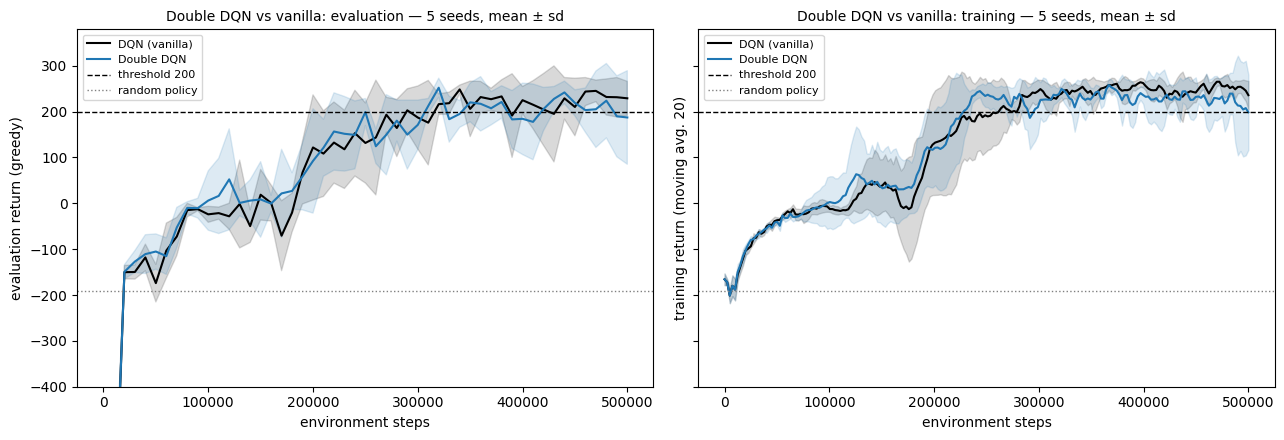

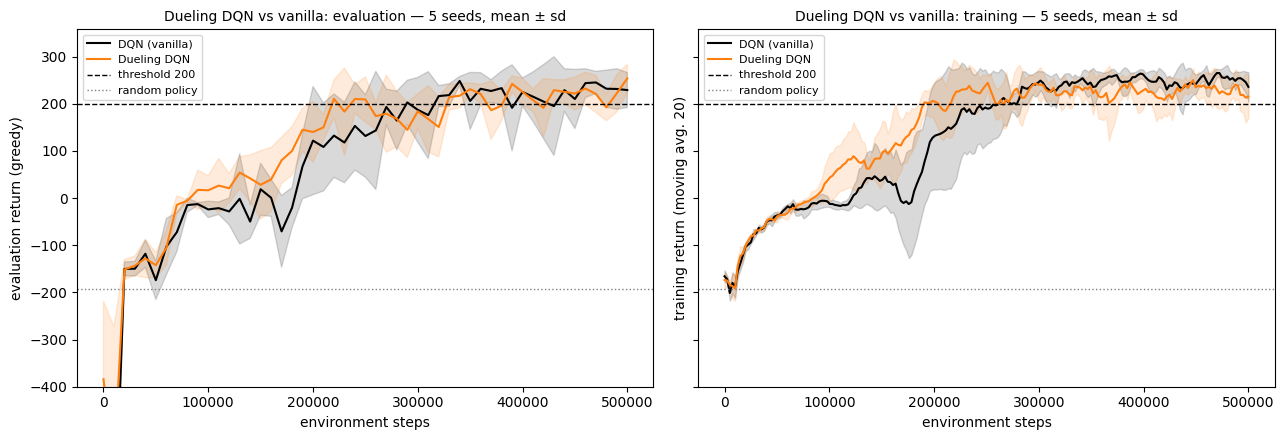

In [12]:
plot_groups(["DQN (vanilla)", "Double DQN"], "Double DQN vs vanilla", "double_vs_vanilla.png")
plot_groups(["DQN (vanilla)", "Dueling DQN"], "Dueling DQN vs vanilla", "dueling_vs_vanilla.png")

### 7.2 All configurations

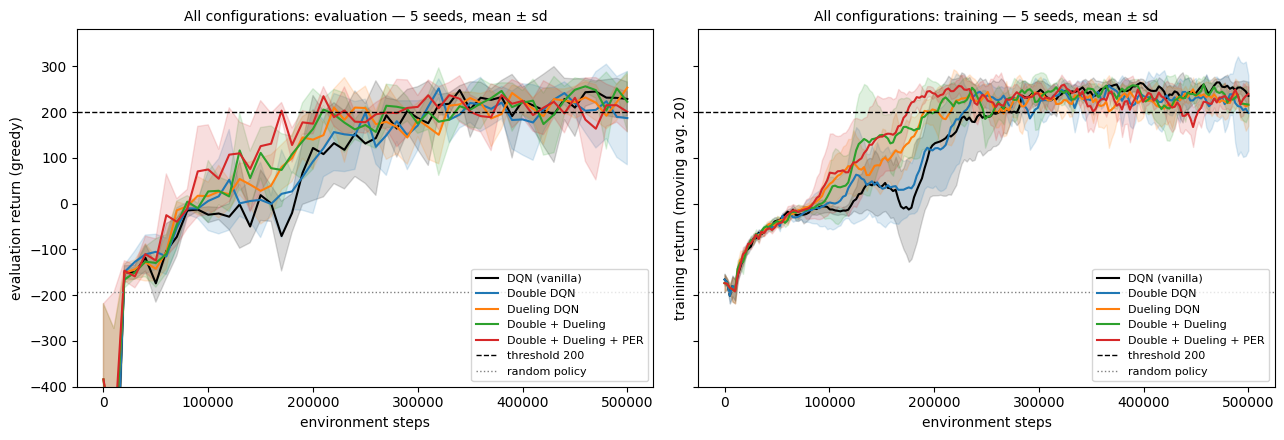

In [13]:
plot_groups(list(GROUPS), "All configurations", "all_configs.png")

### 7.3 Overestimation of Q-values

Left: predicted value $\overline{\max_a Q(s,a)}$ (solid) vs actual discounted return $\overline{G_t}$ (dashed) on the states visited by the greedy policy. Right: the bias $\overline{Q} - \overline{G}$ (positive = overestimation). Double DQN is expected to have a smaller positive bias than vanilla DQN.

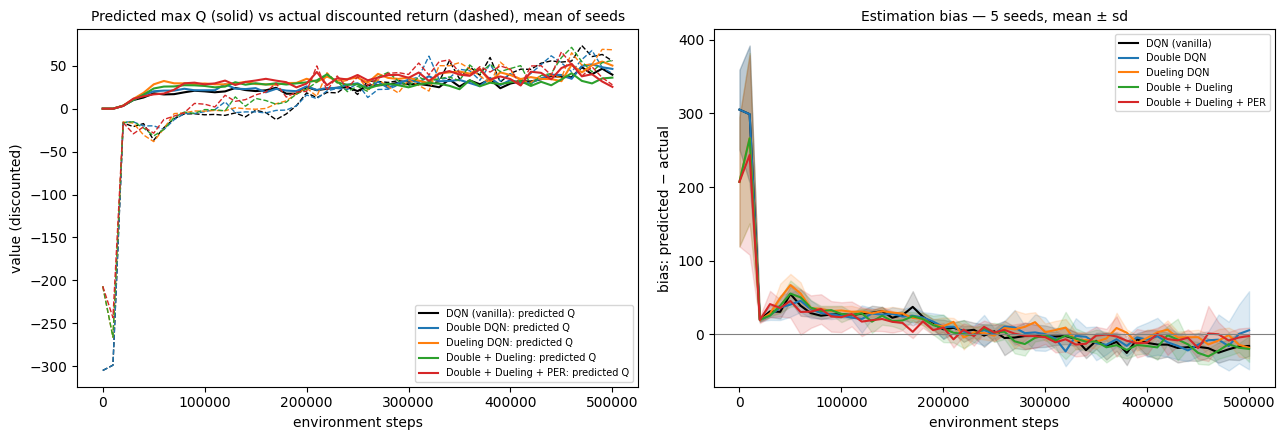

DQN (vanilla)            mean bias (second half) =  -11.77 ±  7.64
Double DQN               mean bias (second half) =   -6.34 ± 10.28
Dueling DQN              mean bias (second half) =   -1.66 ±  3.25
Double + Dueling         mean bias (second half) =  -12.12 ±  5.79
Double + Dueling + PER   mean bias (second half) =   -5.24 ±  6.39


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, logs in GROUPS.items():
    x, Q = eval_curve(logs, "eval_q_pred")
    _, G = eval_curve(logs, "eval_g_true")
    axes[0].plot(x, Q.mean(axis=0), color=COLORS[name], label=f"{name}: predicted Q")
    axes[0].plot(x, G.mean(axis=0), color=COLORS[name], linestyle="--", linewidth=1)
    plot_mean_std(axes[1], x, Q - G, name, color=COLORS[name])
axes[0].set_ylabel("value (discounted)")
axes[0].set_title("Predicted max Q (solid) vs actual discounted return (dashed), mean of seeds", fontsize=10)
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_ylabel("bias: predicted − actual")
axes[1].set_title(f"Estimation bias — {len(SEEDS)} seeds, mean ± sd", fontsize=10)
for ax in axes:
    ax.set_xlabel("environment steps")
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "overestimation.png", dpi=150)
plt.show()

# bias over the second half of training (after the early, very unstable phase)
for name, logs in GROUPS.items():
    x, Q = eval_curve(logs, "eval_q_pred")
    _, G = eval_curve(logs, "eval_g_true")
    late = x >= STEP_BUDGET // 2
    bias = (Q - G)[:, late].mean(axis=1)    # one value per seed
    print(f"{name:24s} mean bias (second half) = {bias.mean():+7.2f} ± {bias.std():5.2f}")

### 7.4 Return vs training time

Same evaluation curves with training wall-clock time (log scale) on the X axis: shows the **cost** of each improvement (PER adds the sum-tree work; dueling and double are almost free).

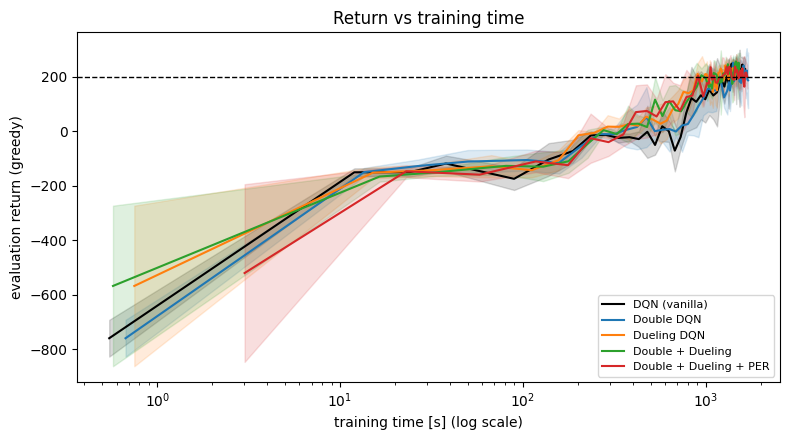

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, logs in GROUPS.items():
    x = np.mean([log["eval_time"] for log in logs], axis=0)
    Y = eval_curve(logs)[1]
    plot_mean_std(ax, x[1:], Y[:, 1:], name, color=COLORS[name])   # skip point 0 (time 0 on a log scale)
ax.axhline(SUCCESS_THRESHOLD, color="black", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("training time [s] (log scale)")
ax.set_ylabel("evaluation return (greedy)")
ax.set_title("Return vs training time")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "walltime.png", dpi=150)
plt.show()

### 7.5 Final return and comparison with vanilla DQN

Left: final return (100 greedy episodes) per configuration; bar = mean, error bar = sd across seeds, dots = seeds.

Right: **difference with vanilla DQN** in final return, with a 95% bootstrap confidence interval over seeds (10,000 resamples). An interval that does not include 0 indicates a difference that is unlikely to be due to seed noise alone; with 5 seeds these intervals are wide, so small differences should not be over-interpreted.

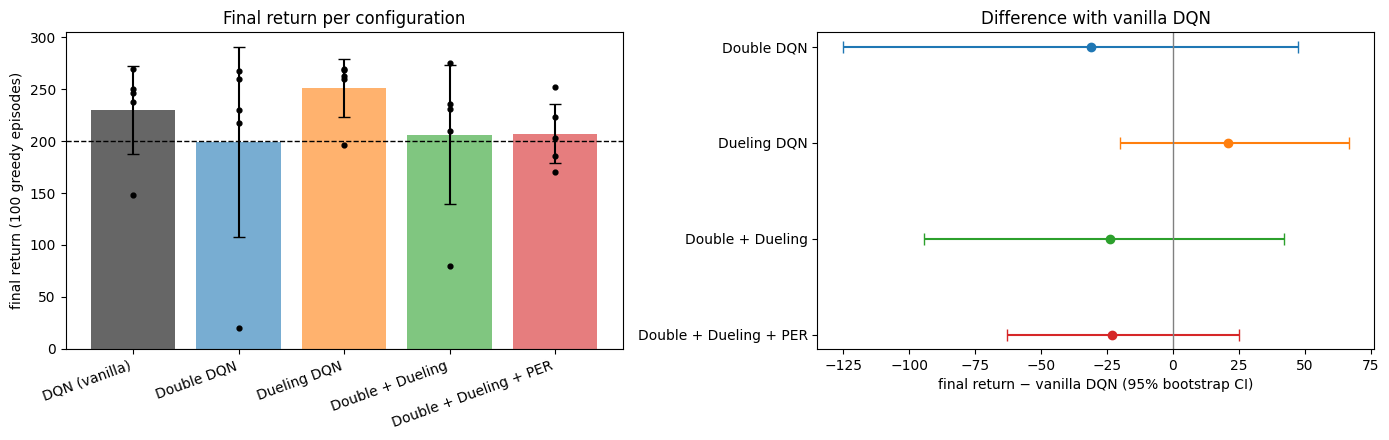

Double DQN               Δ =   -31.0   95% CI [ -125.2,   +47.3]
Dueling DQN              Δ =   +21.0   95% CI [  -20.1,   +66.7]
Double + Dueling         Δ =   -23.8   95% CI [  -94.5,   +42.0]
Double + Dueling + PER   Δ =   -23.1   95% CI [  -63.0,   +24.9]


In [16]:
def bootstrap_diff_ci(a, b, n_boot=10_000, seed=0):
    # 95% CI of mean(a) - mean(b), resampling the seeds of each group independently
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a), np.asarray(b)
    diffs = (rng.choice(a, (n_boot, len(a))).mean(axis=1) - rng.choice(b, (n_boot, len(b))).mean(axis=1))
    return a.mean() - b.mean(), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)


names = list(GROUPS)
finals = np.array([[log["final_return"] for log in GROUPS[n]] for n in names])   # (configs, seeds)
colors = [COLORS[n] for n in names]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
pos = np.arange(len(names))
axes[0].bar(pos, finals.mean(axis=1), yerr=finals.std(axis=1), color=colors, alpha=0.6, capsize=4)
for k in range(len(SEEDS)):
    axes[0].scatter(pos, finals[:, k], color="black", s=12, zorder=3)
axes[0].axhline(SUCCESS_THRESHOLD, color="black", linestyle="--", linewidth=1)
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_xticks(pos)
axes[0].set_xticklabels(names, rotation=20, ha="right")
axes[0].set_ylabel("final return (100 greedy episodes)")
axes[0].set_title("Final return per configuration")

DIFFS = {}
for k, name in enumerate(names[1:], start=1):
    d, lo, hi = bootstrap_diff_ci(finals[k], finals[0])
    DIFFS[name] = (d, lo, hi)
    axes[1].errorbar(d, k, xerr=[[d - lo], [hi - d]], fmt="o", color=COLORS[name], capsize=4)
axes[1].axvline(0, color="gray", linewidth=1)
axes[1].set_yticks(range(1, len(names)))
axes[1].set_yticklabels(names[1:])
axes[1].invert_yaxis()
axes[1].set_xlabel("final return − vanilla DQN (95% bootstrap CI)")
axes[1].set_title("Difference with vanilla DQN")
fig.tight_layout()
fig.savefig(FIG_DIR / "final_returns.png", dpi=150)
plt.show()

for name, (d, lo, hi) in DIFFS.items():
    print(f"{name:24s} Δ = {d:+7.1f}   95% CI [{lo:+7.1f}, {hi:+7.1f}]")

### 7.6 Summary table

- **Final eval**: last 10-episode evaluation (step 500k).
- **Final 100 ep.**: greedy return over 100 episodes, mean ± sd **across seeds**; **Solved** = seeds with ≥ 200.
- **AUC**: mean evaluation return over the whole training (higher = learns faster and/or more stably).
- **Best eval**: best 10-episode evaluation during training.
- **Steps to threshold**: first evaluation ≥ 200 (median over the seeds that reach it), or "not reached".
- **Bias**: mean $\overline{Q} - \overline{G}$ over the second half of training.
- **Time**: training time per run, without evaluation.

In [17]:
lines = [
    "| Configuration | Params | Final eval | Final 100 ep. | Solved | AUC | Best eval | Steps to threshold | Reached | Bias | Time [s] |",
    "| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |",
]
for name, logs in GROUPS.items():
    last_eval = np.array([log["eval_returns"][-1] for log in logs])
    final100 = np.array([log["final_return"] for log in logs])
    auc = np.array([np.mean(log["eval_returns"]) for log in logs])
    best_eval = np.array([max(log["eval_returns"]) for log in logs])
    times = np.array([log["train_time"] for log in logs])
    solved = int(np.sum(final100 >= SUCCESS_THRESHOLD))
    x, Q = eval_curve(logs, "eval_q_pred")
    _, G = eval_curve(logs, "eval_g_true")
    bias = (Q - G)[:, x >= STEP_BUDGET // 2].mean(axis=1)

    hits = []
    for log in logs:
        step = steps_to_threshold(log)
        if step is not None:
            hits.append(step)
    if len(hits) > 0:
        hit_text = f"{int(np.median(hits)):,}"
    else:
        hit_text = "not reached"

    lines.append(f"| {name} | {logs[0]['num_params']:,} | {last_eval.mean():.1f} ± {last_eval.std():.1f} "
                 f"| {final100.mean():.1f} ± {final100.std():.1f} | {solved}/{len(logs)} "
                 f"| {auc.mean():.1f} ± {auc.std():.1f} | {best_eval.mean():.1f} ± {best_eval.std():.1f} "
                 f"| {hit_text} | {len(hits)}/{len(logs)} | {bias.mean():+.1f} ± {bias.std():.1f} "
                 f"| {times.mean():.0f} ± {times.std():.0f} |")

table = "\n".join(lines)
first_log = LOGS[f"vanilla_s{SEEDS[0]}"]
train_hardware = first_log["hardware"]   # machine where the runs were trained
parallel = first_log.get("n_jobs", 1)
header = (f"Hardware: {train_hardware} | runs trained in parallel: {parallel} (1 CPU thread each) | "
          f"budget {STEP_BUDGET:,} steps | seeds {SEEDS}")
(RESULTS_DIR / "summary.md").write_text(f"{header}\n\n{table}\n")
display(Markdown(table))
print(header)

| Configuration | Params | Final eval | Final 100 ep. | Solved | AUC | Best eval | Steps to threshold | Reached | Bias | Time [s] |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| DQN (vanilla) | 69,124 | 229.0 ± 37.0 | 230.0 ± 42.3 | 4/5 | 73.3 ± 30.6 | 271.7 ± 9.3 | 210,000 | 5/5 | -11.8 ± 7.6 | 1643 ± 700 |
| Double DQN | 69,124 | 187.2 ± 102.0 | 199.0 ± 91.1 | 4/5 | 76.8 ± 17.4 | 270.0 ± 8.1 | 250,000 | 5/5 | -6.3 ± 10.3 | 1709 ± 709 |
| Dueling DQN | 68,741 | 253.8 ± 29.5 | 251.1 ± 27.5 | 4/5 | 100.5 ± 8.9 | 274.8 ± 6.6 | 220,000 | 5/5 | -1.7 ± 3.3 | 1478 ± 728 |
| Double + Dueling | 68,741 | 222.8 ± 65.3 | 206.2 ± 66.5 | 4/5 | 107.3 ± 13.5 | 272.8 ± 8.5 | 190,000 | 5/5 | -12.1 ± 5.8 | 1533 ± 752 |
| Double + Dueling + PER | 68,741 | 200.9 ± 43.6 | 207.0 ± 28.5 | 3/5 | 120.1 ± 8.8 | 273.3 ± 3.1 | 160,000 | 5/5 | -5.2 ± 6.4 | 1690 ± 864 |

Hardware: Intel64 Family 6 Model 183 Stepping 1, GenuineIntel, 32 CPUs, Windows | runs trained in parallel: 12 (1 CPU thread each) | budget 500,000 steps | seeds [0, 1, 2, 3, 4]


## 8. GIF of the trained agents

For each configuration, the run with the highest final return (same initial state for all, so the landings can be compared directly).

DQN (vanilla): vanilla_s2, return of the recorded episode = 256


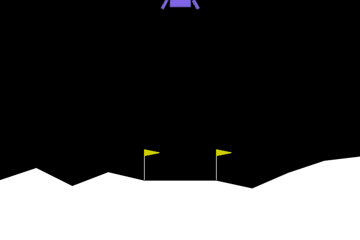

Double DQN: double_s2, return of the recorded episode = 268


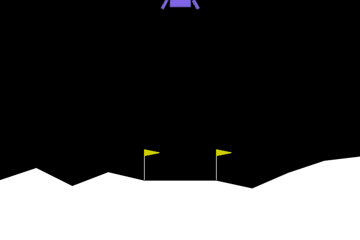

Dueling DQN: dueling_s3, return of the recorded episode = 262


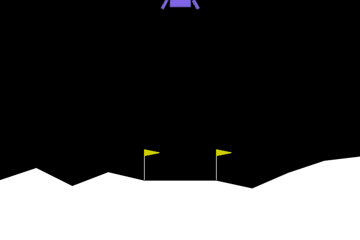

Double + Dueling: double_dueling_s1, return of the recorded episode = 266


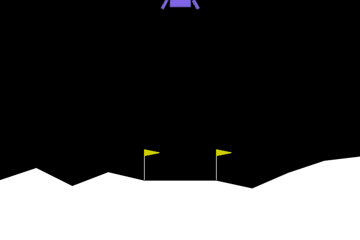

Double + Dueling + PER: double_dueling_per_s4, return of the recorded episode = 262


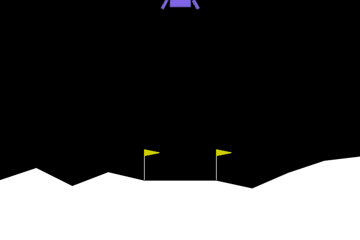

In [18]:
def load_q_net(name):
    env = gym.make(ENV_ID)
    state_dim, n_actions = env.observation_space.shape[0], env.action_space.n
    env.close()
    config = LOGS[name]["config"]
    Net = DuelingQNetwork if config["dueling"] else QNetwork
    q_net = Net(state_dim, n_actions, config["hidden"])
    q_net.load_state_dict(torch.load(MODEL_DIR / f"{name}.pt"))
    return q_net


def record_gif(q_net, path):
    env = gym.make(ENV_ID, render_mode="rgb_array")
    state, _ = env.reset(seed=FINAL_SEED)
    frames = [env.render()]
    done = False
    total_reward = 0.0
    while not done:
        state, reward, terminated, truncated, _ = env.step(select_action(q_net, state, 0.0, env.action_space.n))
        frames.append(env.render())
        total_reward += reward
        done = terminated or truncated
    env.close()
    images = [Image.fromarray(frame).resize((360, 240)) for frame in frames[::2]]   # 1 of every 2 frames
    images[0].save(path, save_all=True, append_images=images[1:], duration=40, loop=0)
    return total_reward


for label, (prefix, _) in EXPERIMENTS.items():
    runs = [f"{prefix}_s{seed}" for seed in SEEDS]
    best = max(runs, key=lambda name: LOGS[name]["final_return"])   # highest return over the 100 final episodes
    path = FIG_DIR / f"{prefix}_best.gif"
    ret = record_gif(load_q_net(best), path)
    print(f"{label}: {best}, return of the recorded episode = {ret:.0f}")
    display(ShowImage(filename=str(path)))